In [ ]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
from scipy.stats import shapiro, pearsonr
from statsmodels.stats.stattools import durbin_watson
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

# Menghilangkan peringatan teks merah agar output rapi
warnings.filterwarnings('ignore')

In [ ]:
df = pd.read_csv('hasil_kuesioner.csv')
df.head(10)

,Timestamp,Apakah Anda sudah atau sedang mengambil mata kuliah Delivery in English?,Beelingua Journey apa yang telah Anda ambil? \n\nCatatan: Beelingua Journey adalah level yang diambil sesuai kemampuan Anda setelah menyelesaikan Beelingua Placement Test. Biasanya masing-masing Journey melingkupi:\n- Journey A Rookie: Basic English & Independent English \n- Journey B Explorer: Independent English & Proficient English\n- Journey C Maverick: Proficient English & Chinese/Japanese (optional),"Apakah Anda pernah mengambil kursus/pelatihan Bahasa Inggris di luar kampus (misalnya: les privat, Duolingo, IELTS preparation)?",Berapa Nilai rata - rata Anda pada mata kuliah berikut? [Data Mining and Visualization],Berapa Nilai rata - rata Anda pada mata kuliah berikut? [Data Structures],Berapa Nilai rata - rata Anda pada mata kuliah berikut? [Data Management and Organization],Berapa Nilai rata - rata Anda pada mata kuliah berikut? [Machine Learning],"Saya secara aktif mengonsumsi konten berbahasa Inggris tanpa subtitle bahasa Indonesia (misal: YouTube, Film, Podcast).",Saya merasa percaya diri saat harus mempresentasikan hasil project atau analisis menggunakan bahasa Inggris secara lisan di depan kelas.,...,"""I can't go out with you guys tonight because I am completely exhausted."" What is the closest meaning of the word 'exhausted' in this sentence?","""_____ it was raining heavily, Jimmy still went out to buy some groceries.""","Read the following message: \n\n""Hi Mandy, I'm running late because the traffic is terrible. Can you please order a cappuccino for me first? I should be at the cafe in about 15 minutes.""\n\nBased on the message, what does the sender want the receiver to do?","""She ____ to the library every Saturday.""","""Please be quiet. The baby ____.""","""She felt nervous before her presentation.""\n\nThe word ""nervous"" is closest in meaning to:","""The movie was so fascinating that I watched it twice.""\n\nWhat does ""fascinating"" mean?","Read the passage:\n\n""Tom studied hard for the exam every evening for two weeks. On the day the results came out, he was very happy.""\n\nWhy was Tom happy?","A: ""I'm sorry I'm late.""\nB: ""____""",Which sentence is correct?
0,5/19/2026 14:47:47,Ya,Journey C Maverick,"Ya, lebih dari 6 bulan",B,A,B -,A -,5,4,...,Very tired,Even though,Buy a coffee for them.,goes,is sleeping,excited,very interesting,He likely got a good result.,That's okay.,She doesn't like coffee.
1,5/19/2026 14:53:06,Ya,Journey B Explorer,Tidak pernah,D,C,B+,A -,3,1,...,Very tired,Even though,Pick them up from the traffic.,go,is sleeping,worried,very interesting,He likely got a good result.,That's okay.,She doesn't likes coffee.
2,5/20/2026 11:28:47,Ya,Journey B Explorer,"Ya, kurang dari 6 bulan",B+,A -,A -,A -,5,3,...,Very tired,Even though,Buy a coffee for them.,goes,is sleeping,worried,very interesting,He likely got a good result.,That's okay.,She doesn't like coffee.
3,5/20/2026 14:52:08,Ya,Journey B Explorer,"Ya, kurang dari 6 bulan",B+,B+,A,A -,4,1,...,Very tired,Even though,Buy a coffee for them.,goes,sleeps,worried,very interesting,He likely got a good result.,That's okay.,She doesn't like coffee.
4,5/20/2026 15:18:26,Ya,Journey B Explorer,Tidak pernah,A -,A -,A -,A,4,3,...,Very tired,Even though,Buy a coffee for them.,goes,is sleeping,worried,very interesting,He likely got a good result.,That's okay.,She doesn't like coffee.
5,5/21/2026 7:44:50,Ya,Journey B Explorer,Tidak pernah,A,A,A,A,3,2,...,Very tired,Even though,Buy a coffee for them.,goes,is sleeping,worried,very interesting,He likely got a good result.,That's okay.,She doesn't like coffee.
6,5/21/2026 9:14:43,Ya,Journey B Explorer,"Ya, lebih dari 6 bulan",D,B,D,A -,4,3,...,Very tired,Even though,Buy a coffee for them.,goes,is sleeping,worried,very interesting,He likely got a good result.,That's okay.,She doesn't like coffee.
7,5/21/2026 10:29:23,Ya,Journey C Maverick,"Ya, lebih dari 6 bulan",A,A,A -,A,5,5,...,Very tired,Even though,Buy a coffee fo

In [ ]:
df.shape

(70, 32)

In [ ]:
# Hapus baris yang tidak memenuhi syarat
kolom_screening = 'Apakah Anda sudah atau sedang mengambil mata kuliah Delivery in English? '
df = df[df[kolom_screening] != 'Tidak'].copy()

In [ ]:
df.shape

(69, 32)

In [ ]:
# DESCRIPTIVE ANALYSIS (MISSING VALUES)

print("==========================================================")
print("MISSING VALUE")
print("==========================================================")
print("Jumlah data kosong (missing value) pada kolom awal:")
print(df.isnull().sum().head())
print("\n")

MISSING VALUE
Jumlah data kosong (missing value) pada kolom awal:
Timestamp                                                                                                                                                                                                                                                                                                                                                                                                                   0
Apakah Anda sudah atau sedang mengambil mata kuliah Delivery in English?                                                                                                                                                                                                                                                                                                                                                    0
Beelingua Journey apa yang telah Anda ambil? \n\nCatatan: Beelingua Journey adalah level yang diambil sesu

In [ ]:
# 2. PREPROCESSING (CODING & VALIDITAS)

# A. Variabel Y (Mengubah Nilai Huruf ke Bobot Nilai)
cols_matkul = [
    'Berapa Nilai rata - rata Anda pada mata kuliah berikut? [Data Mining and Visualization]',
    'Berapa Nilai rata - rata Anda pada mata kuliah berikut? [Data Structures]',
    'Berapa Nilai rata - rata Anda pada mata kuliah berikut? [Data Management and Organization]',
    'Berapa Nilai rata - rata Anda pada mata kuliah berikut? [Machine Learning]'
]

grade_map = {'A': 4.00, 'A -': 3.67, 'B+': 3.33, 'B': 3.00, 'B -': 2.50, 'C': 2.00, 'D': 1.00}

for c in cols_matkul:
    df[c + '_num'] = df[c].astype(str).str.strip().map(grade_map)

df['Y_Nilai_Matkul'] = df[[c + '_num' for c in cols_matkul]].mean(axis=1)

df_clean = df.copy()

In [ ]:
# B. Variabel X1 (Skoring 11 Soal Tes)
answer_key = {
    '  "Yesterday, I _____ to the mall and _____ a new pair of shoes."  ': 'went / bought',
    '"I can\'t go out with you guys tonight because I am completely exhausted." What is the closest meaning of the word \'exhausted\' in this sentence?  ': 'Very tired',
    '"_____ it was raining heavily, Jimmy still went out to buy some groceries."  ': 'Even though',
    'Read the following message: \n\n"Hi Mandy, I\'m running late because the traffic is terrible. Can you please order a cappuccino for me first? I should be at the cafe in about 15 minutes."\n\nBased on the message, what does the sender want the receiver to do?': 'Buy a coffee for them.',
    '"She ____ to the library every Saturday."': 'goes',
    '"Please be quiet. The baby ____."': 'is sleeping',
    '"She felt nervous before her presentation."\n\nThe word "nervous" is closest in meaning to:': 'worried',
    '"The movie was so fascinating that I watched it twice."\n\nWhat does "fascinating" mean?': 'very interesting',
    'Read the passage:\n\n"Tom studied hard for the exam every evening for two weeks. On the day the results came out, he was very happy."\n\nWhy was Tom happy?': 'He likely got a good result.',
    'A: "I\'m sorry I\'m late."\nB: "____"': "That's okay.",
    'Which sentence is correct?': "She doesn't like coffee."
}

score_cols = []
for i, col in enumerate(answer_key.keys()):
    col_name = f'Q{i+1}_score'
    df_clean[col_name] = (df_clean[col] == answer_key[col]).astype(int)
    score_cols.append(col_name)

df_clean['X1_Skor_Tes'] = df_clean[score_cols].sum(axis=1)

In [ ]:
# C. Variabel X2 (Mengubah Level ke Angka)
def map_beelingua(val):
    val = str(val).lower()
    if 'rookie' in val: return 1
    elif 'explorer' in val: return 2
    elif 'maverick' in val: return 3
    else: return 1

col_beelingua = [c for c in df_clean.columns if 'Beelingua Journey' in c][0]
df_clean['X2_Level_Beelingua'] = df_clean[col_beelingua].apply(map_beelingua)

In [ ]:
# D. Variabel X3 (Menjumlahkan Skala Kebiasaan)
cols_habits = [
    'Saya secara aktif mengonsumsi konten berbahasa Inggris tanpa subtitle bahasa Indonesia (misal: YouTube, Film, Podcast).  ',
    'Saya merasa percaya diri saat harus mempresentasikan hasil project atau analisis menggunakan bahasa Inggris secara lisan di depan kelas.  ',
    'Saya terbiasa dan mampu membaca dokumentasi teknis atau library koding dalam bahasa Inggris tanpa bantuan alat penerjemah.  '
]
df_clean['X3_Kebiasaan'] = df_clean[cols_habits].sum(axis=1)

In [ ]:
# ==========================================
# MENAMPILKAN OUTPUT HASIL TAHAP 2
# ==========================================
print("==========================================================")
print("HASIL PREPROCESSING & VALIDITAS")
print("==========================================================")

# Menampilkan cuplikan data yang sudah berubah jadi angka
print("Cuplikan 5 Data Pertama Setelah Preprocessing (Coding):")
kolom_inti = ['Y_Nilai_Matkul', 'X1_Skor_Tes', 'X2_Level_Beelingua', 'X3_Kebiasaan']
print(df_clean[kolom_inti].head())
print("\n")

HASIL PREPROCESSING & VALIDITAS
Cuplikan 5 Data Pertama Setelah Preprocessing (Coding):
   Y_Nilai_Matkul  X1_Skor_Tes  X2_Level_Beelingua  X3_Kebiasaan
0          3.2925           10                   3            14
1          2.5000            7                   2             7
2          3.5850           11                   2            12
3          3.5825           10                   2             6
4          3.7525           10                   2            11




In [ ]:
# 3. UJI RELIABILITAS

# Cetak Bukti Reliabilitas
def cronbach_alpha(df_items):
    k = df_items.shape[1]
    var_items = df_items.var(axis=0, ddof=1).sum()
    var_total = df_items.sum(axis=1).var(ddof=1)
    if var_total == 0: return 0
    return (k / (k - 1)) * (1 - (var_items / var_total))

# Realibilitas X1 ()
alpha_x1 = cronbach_alpha(df_clean[score_cols])
status_alpha_x1 = "Reliabel" if alpha_x1 > 0.6 else "Tidak Reliabel"

# Realibilitas X3
cols_habits = [
    'Saya secara aktif mengonsumsi konten berbahasa Inggris tanpa subtitle bahasa Indonesia (misal: YouTube, Film, Podcast).  ',
    'Saya merasa percaya diri saat harus mempresentasikan hasil project atau analisis menggunakan bahasa Inggris secara lisan di depan kelas.  ',
    'Saya terbiasa dan mampu membaca dokumentasi teknis atau library koding dalam bahasa Inggris tanpa bantuan alat penerjemah.  '
]

alpha_x3 = cronbach_alpha(df_clean[cols_habits])
status_alpha_x3 = "Reliabel" if alpha_x3 > 0.6 else "Tidak Reliabel"

print("==========================================================")
print("UJI RELIABILITAS")
print("==========================================================")
print(f"Uji Reliabilitas X1 (Cronbach's Alpha): {alpha_x1:.3f} => {status_alpha_x1}")
print(f"Uji Reliabilitas X3 (Cronbach's Alpha): {alpha_x3:.3f} => {status_alpha_x3}\n")

UJI RELIABILITAS
Uji Reliabilitas X1 (Cronbach's Alpha): 0.736 => Reliabel
Uji Reliabilitas X3 (Cronbach's Alpha): 0.706 => Reliabel



DESCRIPTIVE ANALYSIS (SUMMARY STATISTICS)
Ringkasan Statistik (Count, Mean, Standar Deviasi, Min, Max) untuk 11 Variabel Utama:
       Q1_score  Q2_score  Q3_score  Q4_score  Q5_score  Q6_score  Q7_score  \
count     69.00     69.00     69.00     69.00     69.00     69.00     69.00   
mean       0.81      0.88      0.81      0.94      0.88      0.80      0.94   
std        0.39      0.32      0.39      0.24      0.32      0.41      0.24   
min        0.00      0.00      0.00      0.00      0.00      0.00      0.00   
25%        1.00      1.00      1.00      1.00      1.00      1.00      1.00   
50%        1.00      1.00      1.00      1.00      1.00      1.00      1.00   
75%        1.00      1.00      1.00      1.00      1.00      1.00      1.00   
max        1.00      1.00      1.00      1.00      1.00      1.00      1.00   

       Q8_score  Q9_score  Q10_score  Q11_score  X1_Skor_Tes  \
count      69.0     69.00      69.00      69.00        69.00   
mean        1.0      0.96       

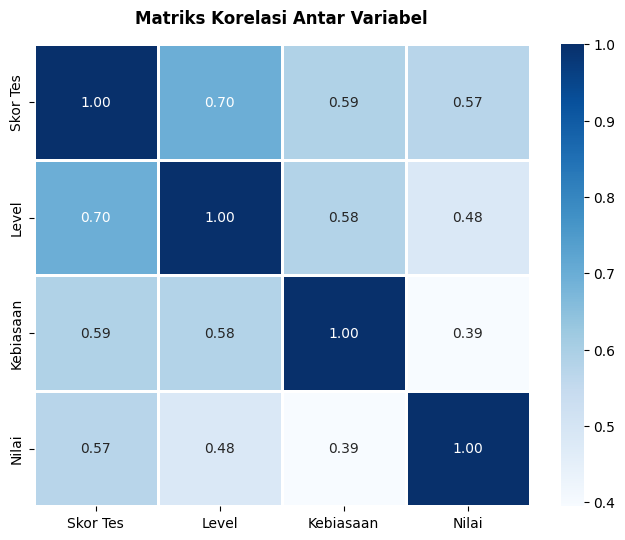

In [ ]:
# 4. DESCRIPTIVE ANALYSIS (SUMMARY STATS)

print("==========================================================")
print("DESCRIPTIVE ANALYSIS (SUMMARY STATISTICS)")
print("==========================================================")
kolom_deskriptif = score_cols + ['X1_Skor_Tes', 'X2_Level_Beelingua', 'X3_Kebiasaan', 'Y_Nilai_Matkul']
print("Ringkasan Statistik (Count, Mean, Standar Deviasi, Min, Max) untuk 11 Variabel Utama:")
print(df_clean[kolom_deskriptif].describe().round(2))
print("\n")

# Grafik 1: Heatmap Korelasi
plt.figure(figsize=(8, 6))
data_korelasi = df_clean[['X1_Skor_Tes', 'X2_Level_Beelingua', 'X3_Kebiasaan', 'Y_Nilai_Matkul']]
sns.heatmap(data_korelasi.corr(), annot=True, cmap='Blues', fmt=".2f", linewidths=1,
            xticklabels=['Skor Tes', 'Level', 'Kebiasaan', 'Nilai'],
            yticklabels=['Skor Tes', 'Level', 'Kebiasaan', 'Nilai'])
plt.title('Matriks Korelasi Antar Variabel', pad=15, fontweight='bold')
plt.show()

HASIL UJI REGRESI & ASUMSI KLASIK
1. Uji Normalitas (Shapiro-Wilk) : p-value = 0.0035 => Tidak Normal
2. Uji Autokorelasi (D-W)        : D-W value = 2.002 => Bebas Autokorelasi

3. Tabel Regresi Linear Berganda:
                            OLS Regression Results                            
Dep. Variable:         Y_Nilai_Matkul   R-squared:                       0.345
Model:                            OLS   Adj. R-squared:                  0.314
Method:                 Least Squares   F-statistic:                     11.39
Date:                Mon, 29 Jun 2026   Prob (F-statistic):           4.26e-06
Time:                        09:46:47   Log-Likelihood:                -19.425
No. Observations:                  69   AIC:                             46.85
Df Residuals:                      65   BIC:                             55.79
Df Model:                           3                                         
Covariance Type:            nonrobust                                        

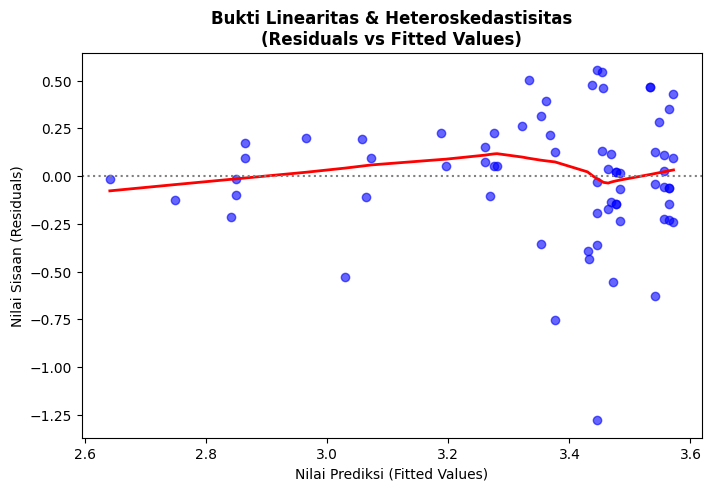

In [ ]:
# 5. UJI REGRESI FINAL & ASUMSI KLASIK

X = df_clean[['X1_Skor_Tes', 'X2_Level_Beelingua', 'X3_Kebiasaan']]
Y = df_clean['Y_Nilai_Matkul']
X_sm = sm.add_constant(X)
model_final = sm.OLS(Y, X_sm).fit()
residuals = model_final.resid

print("==========================================================")
print("HASIL UJI REGRESI & ASUMSI KLASIK")
print("==========================================================")
# Cetak Bukti Normalitas
stat, p_shapiro = shapiro(residuals)
status_norm = "Normal" if p_shapiro > 0.05 else "Tidak Normal"
print(f"1. Uji Normalitas (Shapiro-Wilk) : p-value = {p_shapiro:.4f} => {status_norm}")

# Cetak Bukti Autokorelasi
dw = durbin_watson(residuals)
status_auto = "Bebas Autokorelasi" if 1.5 < dw < 2.5 else "Ada Autokorelasi"
print(f"2. Uji Autokorelasi (D-W)        : D-W value = {dw:.3f} => {status_auto}\n")

print("3. Tabel Regresi Linear Berganda:")
print(model_final.summary())

# Grafik 1: Bukti Linearitas (Residuals vs Fitted)
plt.figure(figsize=(8,5))
sns.regplot(x=model_final.fittedvalues, y=residuals, lowess=True,
            scatter_kws={'alpha':0.6, 'color':'blue'},
            line_kws={'color':'red', 'lw':2})
plt.axhline(y=0, color='gray', linestyle=':')
plt.title('Bukti Linearitas & Heteroskedastisitas\n(Residuals vs Fitted Values)', fontweight='bold')
plt.xlabel('Nilai Prediksi (Fitted Values)')
plt.ylabel('Nilai Sisaan (Residuals)')
plt.show()

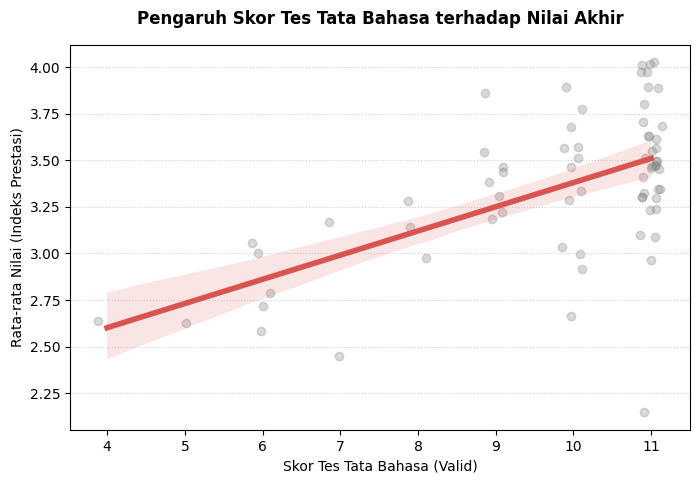

In [ ]:
# 6. VISUALISASI PRESENTASI

# Grafik 3: Scatter Plot Utama (X1 vs Y)
plt.figure(figsize=(8, 5))
sns.regplot(x=df_clean['X1_Skor_Tes'], y=df_clean['Y_Nilai_Matkul'],
            scatter_kws={'alpha':0.3, 'color':'gray'},
            line_kws={'color':'#d9534f', 'lw':4},
            x_jitter=0.15, y_jitter=0.05)
plt.title('Pengaruh Skor Tes Tata Bahasa terhadap Nilai Akhir', pad=15, fontweight='bold')
plt.xlabel('Skor Tes Tata Bahasa (Valid)')
plt.ylabel('Rata-rata Nilai (Indeks Prestasi)')
plt.grid(axis='y', linestyle=':', alpha=0.6)
plt.show()

## Penelusuran Potensi Response Bias pada X3_Kebiasaan

Response bias, terutama *social desirability bias* (bias keinginan sosial), sangat relevan untuk variabel `X3_Kebiasaan` karena ini adalah ukuran yang dilaporkan sendiri mengenai kebiasaan dan kepercayaan diri dalam berbahasa Inggris. Responden mungkin cenderung melaporkan kebiasaan yang lebih baik dari kenyataan agar terlihat lebih positif atau sesuai norma sosial.

**Mengapa sulit menghitung 'Response Bias' secara langsung dari data ini?**

Untuk mengukur 'response bias' secara kuantitatif, kita memerlukan 'nilai sebenarnya' (true value) yang objektif untuk `X3_Kebiasaan` untuk setiap responden. Response bias kemudian akan dihitung sebagai selisih antara nilai yang dilaporkan (`X3_Kebiasaan`) dan 'nilai sebenarnya'.

**Pendekatan 'True Value' untuk `X3_Kebiasaan`:**

Pada data Anda, `X3_Kebiasaan` dihitung berdasarkan penjumlahan skor dari 3 pernyataan kebiasaan yang dilaporkan sendiri. Untuk mendapatkan 'true value' yang objektif, kita akan memerlukan:

*   **Observasi Langsung**: Misalnya, melacak secara objektif berapa jam responden benar-benar mengonsumsi konten berbahasa Inggris atau menilai langsung kemampuan presentasi lisan mereka melalui panel ahli.
*   **Data Sekunder yang Terverifikasi**: Misalnya, catatan dari kursus bahasa Inggris eksternal yang menunjukkan frekuensi partisipasi atau penilaian kemajuan yang objektif.

Karena data 'true value' yang objektif tersebut tidak tersedia dalam dataset `hasil_kuesioner.csv`, kita tidak dapat menghitung 'response bias' secara langsung. Namun, kita bisa menganalisis distribusi data `X3_Kebiasaan` untuk mencari *indikasi* potensi bias.

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

print("==========================================================")
print("ANALISIS DISTRIBUSI X3_Kebiasaan (Indikator Potensi Bias)")
print("==========================================================")

# Memvisualisasikan distribusi X3_Kebiasaan
plt.figure(figsize=(8, 5))
sns.histplot(df_final['X3_Kebiasaan'], kde=True, bins=range(int(df_final['X3_Kebiasaan'].min()), int(df_final['X3_Kebiasaan'].max()) + 2))
plt.title('Distribusi X3_Kebiasaan (Skor Kebiasaan Berbahasa Inggris)', pad=15, fontweight='bold')
plt.xlabel('Skor Kebiasaan (X3_Kebiasaan)')
plt.ylabel('Frekuensi')
plt.grid(axis='y', linestyle=':', alpha=0.6)
plt.xticks(range(int(df_final['X3_Kebiasaan'].min()), int(df_final['X3_Kebiasaan'].max()) + 1))
plt.show()

### Interpretasi Distribusi X3_Kebiasaan:

Dari grafik distribusi `X3_Kebiasaan`:

*   **Kecenderungan Skewness**: Jika distribusinya sangat miring ke kanan (skewed to the right), dengan banyak responden melaporkan nilai tinggi dan sedikit yang melaporkan nilai rendah, ini bisa menjadi *indikasi kualitatif* adanya social desirability bias. Responden mungkin cenderung melebih-lebihkan kebiasaan mereka.
*   **Mean vs. Median**: Bandingkan nilai mean (`11.23`) dan median dari `X3_Kebiasaan`. Jika mean jauh lebih tinggi dari median dan ada penumpukan di skor atas, ini bisa memperkuat dugaan bias.

### Kesimpulan mengenai Response Bias:

Pada dataset ini, kita tidak dapat menghitung 'response bias' secara kuantitatif karena tidak ada 'true value' objektif yang tersedia untuk variabel `X3_Kebiasaan` (self-reported habits).

Namun, analisis distribusi `X3_Kebiasaan` dapat memberikan *petunjuk* tentang potensi bias. Jika distribusi menunjukkan kecenderungan yang kuat ke arah skor tinggi (over-reporting), ini harus diakui sebagai batasan dalam interpretasi hasil, terutama saat menarik kesimpulan tentang sejauh mana 'kebiasaan' responden sebenarnya sesuai dengan laporan mereka. Untuk studi di masa mendatang, disarankan untuk menyertakan metode pengumpulan data objektif atau pertanyaan *check-item* untuk memitigasi dan mendeteksi response bias secara lebih efektif.

In [ ]:
print("==========================================================")
print("SKEWNESS DAN KURTOSIS X3_Kebiasaan")
print("==========================================================")

skewness_x3 = df_final['X3_Kebiasaan'].skew()
kurtosis_x3 = df_final['X3_Kebiasaan'].kurt()

print(f"Skewness (Kemiringan) X3_Kebiasaan: {skewness_x3:.3f}")
print(f"Kurtosis (Keruncingan) X3_Kebiasaan: {kurtosis_x3:.3f}")